In [6]:
import numpy as np
import matplotlib.pyplot as plt

In [4]:
path = 'data/pdebench_burgers_core.npz'

In [62]:
d = np.load(path)
for key in d.files:
    print(f"{key}: shape = {d[key].shape}")

train_field: shape = (240, 128)
train_target: shape = (240, 128)
train_context: shape = (240, 2)
train_coordinates: shape = (128,)
eval_128_field: shape = (60, 128)
eval_128_target: shape = (60, 128)
eval_128_context: shape = (60, 2)
eval_128_coordinates: shape = (128,)
eval_256_field: shape = (60, 256)
eval_256_target: shape = (60, 256)
eval_256_context: shape = (60, 2)
eval_256_coordinates: shape = (256,)
eval_512_field: shape = (60, 512)
eval_512_target: shape = (60, 512)
eval_512_context: shape = (60, 2)
eval_512_coordinates: shape = (512,)


Mean absolute change: 0.011718096
Maximum absolute change: 0.61344814
Change standard deviation: 0.031024555


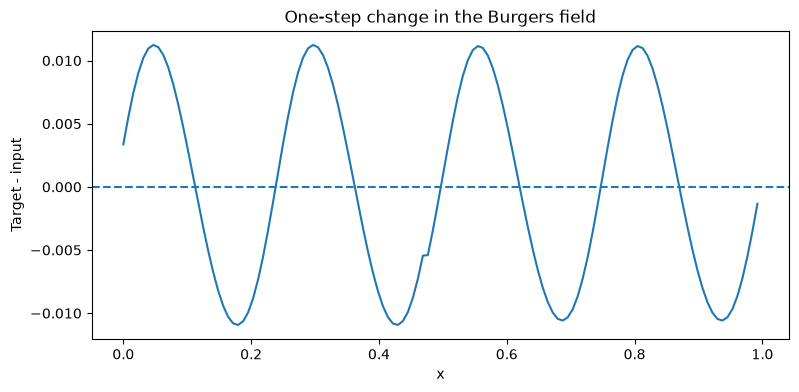

In [63]:
data = np.load('data/train.npz')
change = data['target'] - data['field']

print("Mean absolute change:", np.mean(np.abs(change)))
print("Maximum absolute change:", np.max(np.abs(change)))
print("Change standard deviation:", np.std(change))

plt.figure(figsize=(9, 4))
plt.plot(x, change[0])
plt.axhline(0, linestyle="--")
plt.xlabel("x")
plt.ylabel("Target - input")
plt.title("One-step change in the Burgers field")
plt.show()

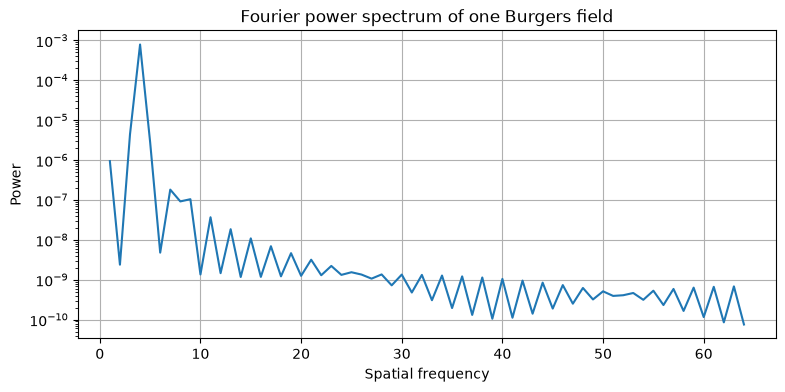

In [64]:
u = data["field"][0]
x = data["coordinates"]

dx = np.mean(np.diff(x))
freq = np.fft.rfftfreq(len(u), d=dx)
power = np.abs(np.fft.rfft(u))**2 / len(u)**2

plt.figure(figsize=(9, 4))
plt.semilogy(freq[1:], power[1:] + 1e-15)
plt.xlabel("Spatial frequency")
plt.ylabel("Power")
plt.title("Fourier power spectrum of one Burgers field")
plt.grid(True)
plt.show()

[1.83574855e+00 1.94052768e+00 2.04237080e+00 2.13918209e+00
 2.22723293e+00 2.29503918e+00 2.28279305e+00 1.80098343e+00
 5.26650131e-01 7.99564868e-02 1.41763389e-02 2.81159626e-03
 5.72283519e-04 1.16489595e-04 2.35549123e-05 4.70805480e-06
 9.22752008e-07 1.90979407e-07 6.49533050e-08 4.74374851e-08
 4.36844516e-08 4.06017193e-08 3.76920042e-08 3.50594647e-08
 3.27392229e-08 3.07488719e-08 2.90934707e-08 2.77660899e-08
 2.67396878e-08 2.58020627e-08 2.35407409e-08 1.68790066e-08
 7.32885397e-09 1.58223712e-09 1.53842092e-10 6.51808902e-12
 1.20715043e-13 9.98886579e-16 3.80987189e-18 6.93611704e-21
 6.24592731e-24 2.87967164e-27 7.02220389e-31 9.33363579e-35
 6.95065758e-39 2.95673976e-43 0.00000000e+00 2.71431513e-41
 5.17087877e-37 5.60715948e-33 3.37290067e-29 1.09392932e-25
 1.85458144e-22 1.58972262e-19 6.65309175e-17 1.31203599e-14
 1.17878743e-12 4.69141496e-11 8.14356527e-10 6.22325880e-09
 2.21493792e-08 3.92349371e-08 5.34527054e-08 7.79211291e-08
 1.89260959e-07 7.731649

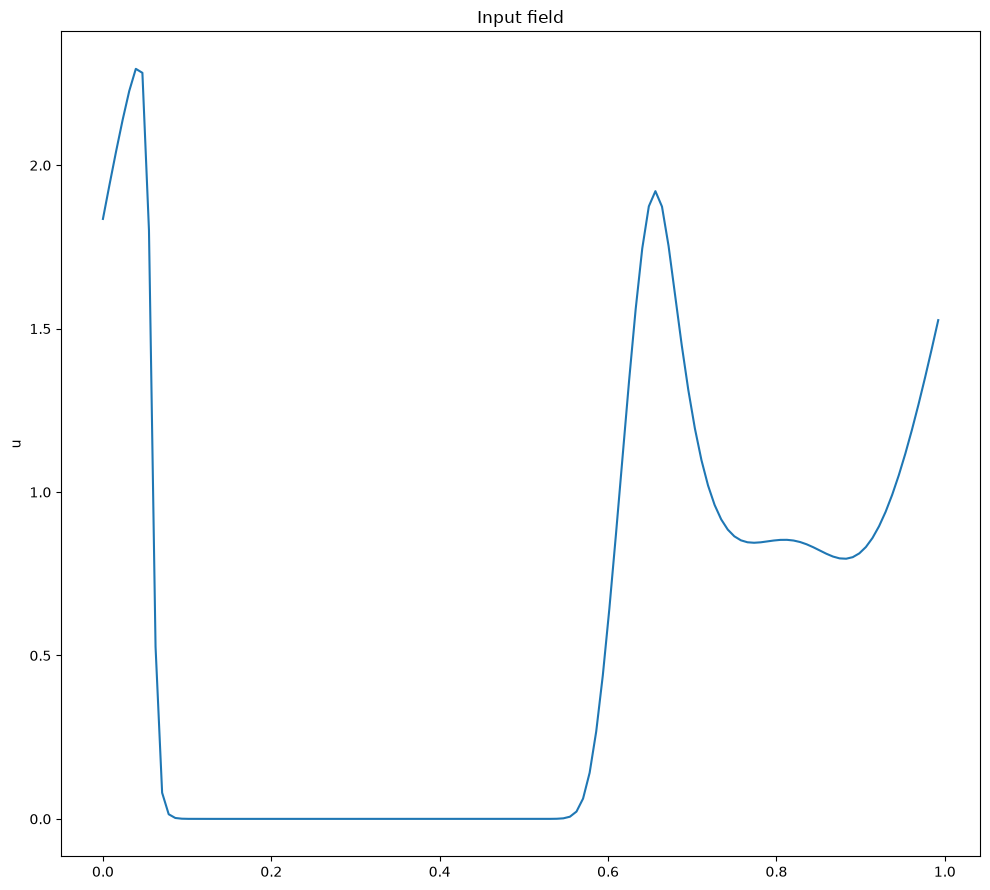

In [123]:
index = 0
x = d['eval_128_coordinates']
u = d['eval_128_field'][index]
print(u,x.shape,u.shape,len(x))

fig, axes = plt.subplots(figsize=(10, 9))
axes.plot(x, u)
axes.set_ylabel("u")
axes.set_title("Input field")
plt.tight_layout()

In [124]:
dx = 1/len(x)   #length/total points
dx

0.0078125

In [125]:
ux = np.gradient(u, dx)
ux

array([ 1.34117279e+01,  1.32238235e+01,  1.27138824e+01,  1.18311768e+01,
        9.97485352e+00,  3.55584717e+00, -3.16195679e+01, -1.12393143e+02,
       -1.10145721e+02, -3.27983246e+01, -4.93727303e+00, -8.70659530e-01,
       -1.72486827e-01, -3.51186320e-02, -7.15401862e-03, -1.44845829e-03,
       -2.89092830e-04, -5.48991156e-05, -9.18668320e-06, -1.36120661e-06,
       -4.37489007e-07, -3.83516635e-07, -3.54704298e-07, -3.16978003e-07,
       -2.75877937e-07, -2.33328137e-07, -1.90898049e-07, -1.50642109e-07,
       -1.25697738e-07, -2.04732601e-07, -5.71075589e-07, -1.03756076e-06,
       -9.78993285e-07, -4.59200749e-07, -1.00846016e-07, -9.83816850e-09,
       -4.17093776e-10, -7.72551901e-12, -6.39282938e-14, -2.43831404e-16,
       -4.43911284e-19, -3.99739297e-22, -1.84298985e-25, -4.49421049e-29,
       -5.97352691e-33, -4.44842085e-37,  1.71823855e-39,  3.30936242e-35,
        3.58858207e-31,  2.15865643e-27,  7.00114763e-24,  1.18693188e-20,
        1.01742181e-17,  

In [126]:
uxx = (np.roll(u, -1) - 2 * u + np.roll(u, 1)) / (dx ** 2)
first_term = -u * ux
secondd_term = (0.01) * uxx
rhs_est = first_term + secondd_term
rhs_est

array([-5.8182201e+01, -2.6142231e+01, -2.6790876e+01, -2.6744354e+01,
       -2.5533197e+01, -2.1276588e+01, -4.7523499e+00,  7.2571121e+01,
        1.9360873e+02,  6.5031303e+01,  8.9854116e+00,  1.4975584e+00,
        2.9231042e-01,  5.9454944e-02,  1.2138718e-02,  2.4676919e-03,
        5.0029065e-04,  9.9245510e-05,  1.7778324e-05,  2.2548950e-06,
        1.0982216e-07,  2.8347147e-08,  4.5412467e-08,  5.1166872e-08,
        5.4049316e-08,  5.4878189e-08,  5.3743140e-08,  4.9312369e-08,
        1.4545225e-08, -2.1687447e-07, -7.2096356e-07, -4.7323843e-07,
        6.2317133e-07,  7.0749746e-07,  2.0989067e-07,  2.3089418e-08,
        1.0285314e-09,  1.9451260e-11,  1.6241029e-13,  6.2193759e-16,
        1.1343672e-18,  1.0223892e-21,  4.7157528e-25,  1.1502121e-28,
        1.5289950e-32,  1.1386988e-36,  4.4955771e-39,  8.4710778e-35,
        9.1850759e-31,  5.5243228e-27,  1.7911885e-23,  3.0349622e-20,
        2.5985262e-17,  1.0848364e-14,  2.1278649e-12,  1.8884415e-10,
      

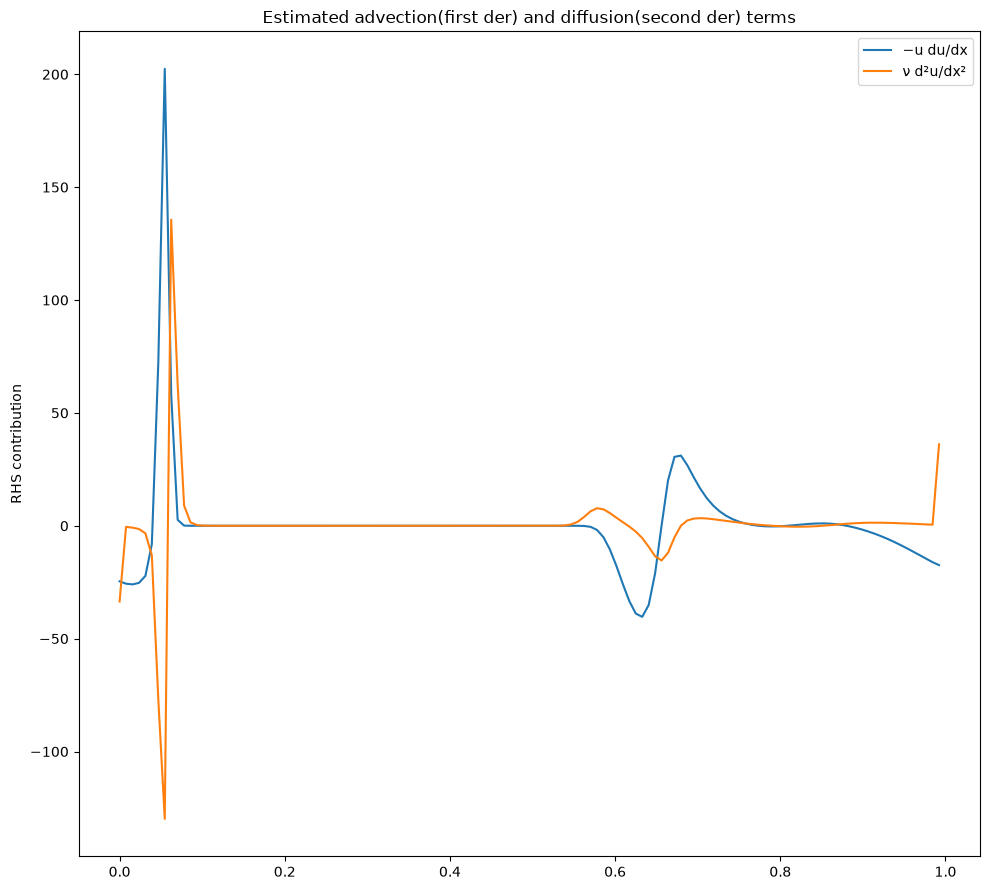

In [127]:
fig, axes = plt.subplots(figsize=(10, 9))
axes.plot(x, first_term, label="−u du/dx")
axes.plot(x, secondd_term, label="ν d²u/dx²")
axes.set_ylabel("RHS contribution")
axes.set_title("Estimated advection(first der) and diffusion(second der) terms")
axes.legend()
plt.tight_layout()

To plot Net instantaneous change

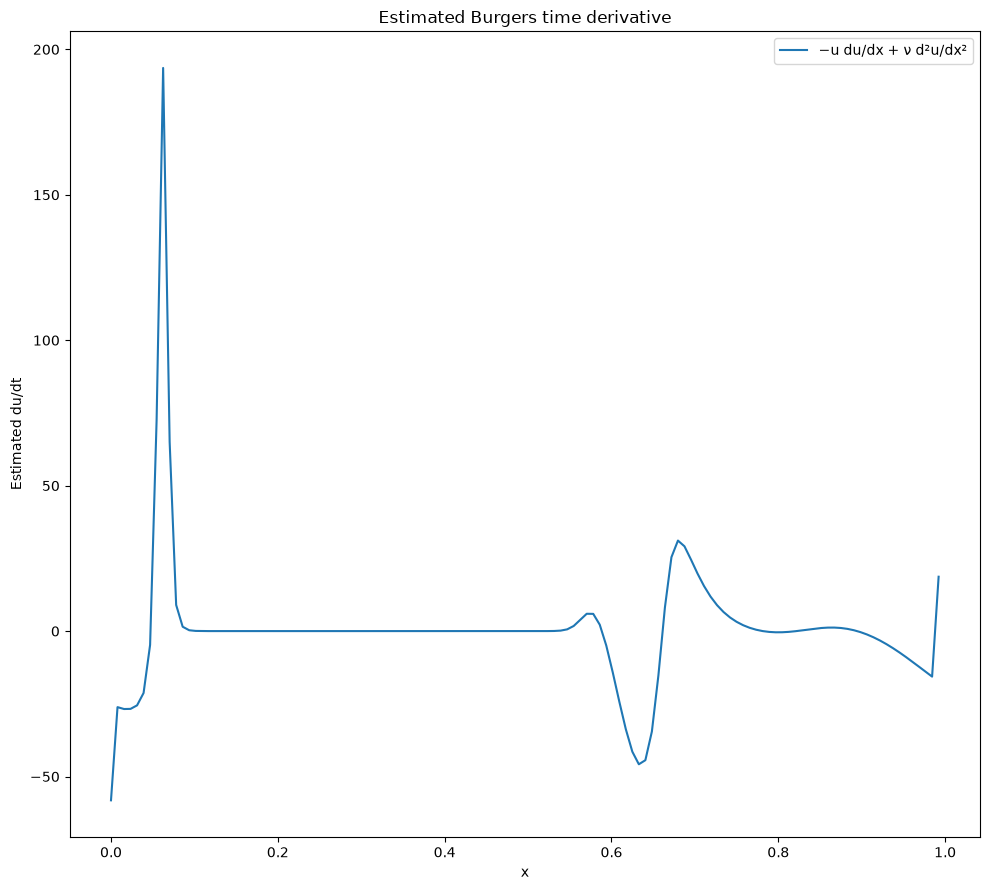

In [128]:
fig, axes = plt.subplots(figsize=(10, 9))
axes.plot(x, rhs_est,
             label="−u du/dx + ν d²u/dx²")
axes.set_xlabel("x")
axes.set_ylabel("Estimated du/dt")
axes.set_title("Estimated Burgers time derivative")
axes.legend()
plt.tight_layout()